# WF5 - Complete workflow: OptimisationSimulation (aPMV setpoints)

WF5 optimises the aPMV setpoints with NSGA-II. The decision variables are the adaptive coefficients of the cooling and heating seasons and the aPMV setpoint s; the two objectives, both minimised, are the annual HVAC electricity and the annual mean operative temperature. Compromise solutions are then chosen from the non-dominated set (knee point and TOPSIS).

The notebook follows Example 5 of the accim paper (optimisation of the aPMV setpoints), with the sample building and weather file distributed with accim instead of the office building of the paper, and a smaller budget. The results are therefore similar in nature, not identical. As in the paper, the solutions are not screened against an adaptive comfort band: the aPMV setpoints do not control the temperature.

To keep the run light, only annual results are kept: the simulation folders are deleted once the results have been read.

In practical terms, we will move through preparation, configuration, execution, and verification so every transition in the workflow stays explicit.
As the notebook progresses, each code cell is introduced with context first, then the call itself, and finally quick guidance on how to interpret the result.

Workflow roadmap:
- Preparation: imports, paths, optimisation budget, a lighter simulation setup (2 timesteps per hour, full-year run period) and the aPMV setpoints.
- Configuration: outputs, objectives and parameter ranges.
- Optimisation: NSGA-II with annual results, the Pareto diagram and the compromise solutions.

Main classes, methods, and functions used in this notebook:
- `OptimisationSimulation`
- `ef.get_building`
- `reduce_runtime`
- `add_vrf_system`
- `apply_apmv_setpoints`
- `set_pmv_input_parameters`
- `optim.discover_available_outputs`
- `optim.select_outputs`
- `optim.apply_outputs_preflight`
- `optim.set_output_readers`
- `optim.set_parameters`
- `optim.set_problem`
- `optim.estimate_optimisation_sims`
- `OptimisationSimulation.run_optimisation`
- `optim.plot_parametric_scatter`
- `optim.plot_best_compromise_solutions`
- `optim.plot_parallel_coordinates`

Narrative structure used in this notebook:
- Each code cell is preceded by an explanatory markdown block.
- Section headings are contextual to the current notebook and execution block.
- Key arguments are described before they are used in code.
- Execution-oriented cells may include a follow-up markdown note to help interpret results.

## WF5 aPMV optimization: import workflow dependencies

We start by loading every dependency required by the full workflow, so the remaining sections can run without hidden imports.

In this complete workflow notebook, imports are intentionally grouped in one place. That makes reruns in a fresh kernel predictable and easier to debug when versions change.

The cell also defines `show_plot_output`, a small helper that displays the figures and image files returned by the plotting methods.

What to verify right after running this cell:
- Review execution output and proceed when values look consistent with the workflow intent.

In [1]:
import os
import random
from pathlib import Path

import pandas as pd
import accim
from besos import eppy_funcs as ef
from besos.objectives import MeterReader, VariableReader
from accim.parametric_and_optimisation.main import OptimisationSimulation
from accim.parametric_and_optimisation.objectives import average_results, sum_results
from accim.sim.apmv_setpoints import add_vrf_system, apply_apmv_setpoints, set_pmv_input_parameters
from accim.utils import reduce_runtime

# (Run once per notebook)
%matplotlib inline
# If you prefer interaction (zoom/pan), use: %matplotlib widget
from IPython.display import Image, display
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 160)


def show_plot_output(plot_output, image_paths=None):
    # Optional deterministic image display for methods that return tabular data.
    if image_paths is not None:
        if isinstance(image_paths, (str, Path)):
            image_paths = [image_paths]
        for plot_path in image_paths:
            display(Image(filename=str(plot_path)))

    if isinstance(plot_output, dict):
        for plot_path in plot_output.values():
            display(Image(filename=str(plot_path)))
        return
    if isinstance(plot_output, (str, Path)):
        display(Image(filename=str(plot_output)))
        return
    if hasattr(plot_output, "fig"):
        display(plot_output.fig)
        plt.show()
        return
    if hasattr(plot_output, "savefig"):
        display(plot_output)
        plt.show()
        return
    if isinstance(plot_output, pd.DataFrame):
        display(plot_output)
        return
    raise TypeError(f"Unsupported plot output type: {type(plot_output)}")


## WF5 aPMV optimization: set project paths, weather file and optimisation budget

Here we declare the project assets (IDF, EPW, and results folder) and the budget of the optimisation.

The IDF and EPW files are the sample files in this folder. If accim was installed with `pip install "accim[samples]"`, copy this folder to a working directory before running the notebook, so that the installed files are not modified; the results are written to `RESULTS_DIRNAME` inside it. Only the Seville weather file is used, because the cooling season of the aPMV setpoints is given by northern-hemisphere dates (see the aPMV setup below).

Key settings in this cell and why they matter:
- `POPULATION_SIZE`: individuals per generation of NSGA-II, 20 as in the paper.
- `EVALUATIONS`: simulations of the optimisation. The paper used 400 per climate; 60 (three generations) keep this example short, and the value can be raised for a better-converged front.
- `SEED`: seed of the random number generator, so the same run can be repeated.
- `PROCESSES`: simulations run in parallel within each generation. Half of the logical CPUs is a safe default.

Variables created in this cell:
- `PROJECT_ROOT`: reused in subsequent workflow blocks.
- `idf_list`: reused in subsequent workflow blocks.
- `epw_list`: reused in subsequent workflow blocks.
- `RESULTS_DIRNAME`: reused in subsequent workflow blocks.
- `POPULATION_SIZE`, `EVALUATIONS`, `SEED`, `PROCESSES`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm that the IDF and EPW files are found.

In [2]:
PROJECT_ROOT = Path.cwd()

idf_list = [
    "OSM_TestResidentialUnit_v01_onlygeometry_SchNatVent_v2520_high_performance.idf",
]
epw_list = ["Seville.epw"]
RESULTS_DIRNAME = "wf5_optimisation_apmv_results"

POPULATION_SIZE = 20
EVALUATIONS = 60
SEED = 20261001
PROCESSES = max(1, (os.cpu_count() or 2) // 2)

print("IDF files found:", [(PROJECT_ROOT / idf).exists() for idf in idf_list])
print("EPW files found:", [(PROJECT_ROOT / epw).exists() for epw in epw_list])
print("Parallel processes:", PROCESSES)


IDF files found: [True]
EPW files found: [True]
Parallel processes: 6


## WF5 aPMV optimization: load the baseline IDF model and make the simulations lighter

Load the base building model used by subsequent runs.

This is where the baseline IDF is loaded for all downstream operations. Later cells reuse this object for output setup, parameterization, and execution. The changes below only affect the model in memory: the IDF file is not modified.

The simulations are made lighter while keeping annual results:
- `reduce_runtime(...)` sets 2 timesteps per hour (the model has 6), minimal shadowing and a lower limit of figures in the shadow overlap calculations. Its run period arguments keep the full year: by default, `reduce_runtime` shortens the run period to 1 January.
- `Run_Simulation_for_Sizing_Periods = "No"`: the design days are still used to size the HVAC system, but they are not simulated as additional environments. Otherwise, the annual results read after each simulation would also include the 7 design days of the sample model (8,928 hours instead of 8,760), and the HVAC electricity would be about 3 % higher.

Fewer timesteps make each simulation faster, with small differences in the annual energy compared with the 6 timesteps of the model. For final results, remove the `reduce_runtime(...)` call, but keep the sizing-period setting.

Variables created in this cell:
- `building`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm that the printed messages report 2 timesteps per hour and MinimalShadowing.

In [3]:
building = ef.get_building(idf_list[0])

reduce_runtime(
    idf_object=building,
    minimal_shadowing=True,
    timesteps=2,
    runperiod_begin_month=1,
    runperiod_begin_day_of_month=1,
    runperiod_end_month=12,
    runperiod_end_day_of_month=31,
)
# Keep the design days out of the annual results.
building.idfobjects["SimulationControl"][0].Run_Simulation_for_Sizing_Periods = "No"


Solar distribution has been set to MinimalShadowing.
Shading Calculation Update Frequency was previously set to 20 days, and it has been modified to 20 days.
Maximum Figures in Shadow Overlap Calculations was previously set to 15000, and it has been modified to 200.
Number of Timesteps per Hour was previously set to 6, and it has been modified to 2.


## WF5 aPMV optimization: add the VRF system and the aPMV setpoints

The aPMV (adaptive Predicted Mean Vote) corrects the PMV for the adaptation of the occupants: aPMV = PMV / (1 + λ PMV), with an adaptive coefficient λ for the cooling season and another for the heating season. The aPMV setpoints keep the aPMV of each zone between −s and +s, so the thermostat works on thermal sensation instead of on temperature.

This cell adds a VRF system with a thermal comfort thermostat to the model and the EMS programs of the aPMV setpoints, with the settings of the examples of the paper:
- cooling season from 1 April to 1 October; the rest of the year is the heating season;
- the default tolerances of accim: the heating setpoint is raised by 0.1 and the cooling setpoint lowered by 0.1.

The adaptive coefficients and the setpoints given here are replaced by the decision variables of the optimisation. `add_vrf_system` already adds a thermal comfort thermostat to each zone, and the model already requests some of the hourly outputs, so the warnings of `apply_apmv_setpoints` about a thermostat or an output variable that already exists are expected: it sets up those thermostats for the aPMV setpoints and skips the repeated outputs.

The PMV also depends on the inputs of the People objects. The sample model uses a constant schedule of 1 for the work efficiency, the clothing insulation and the air velocity: with a work efficiency of 1, all the metabolic heat becomes work, so the occupants would always feel cold and the thermostat would overheat the zones (to an annual mean of about 38 °C). These inputs do not affect temperature setpoints, but they do affect aPMV setpoints, so `set_pmv_input_parameters` sets a work efficiency of 0 and an air velocity of 0.1 m/s, and a seasonal schedule sets the clothing insulation: 1 clo from October to March and 0.5 clo from April to September, the cooling season. (The dynamic clothing model of EnergyPlus cannot be used here: the thermal comfort thermostats need a clothing schedule.)

The cooling season is given by dates, which only describe the seasons of the northern hemisphere. For this reason, this notebook uses only the Seville weather file (the paper also used Seville). For a location in the southern hemisphere, such as Sydney, the dates must be swapped (cooling season from 1 October to 1 April).

Key arguments used in this cell and why they matter:
- `outputs_freq`: frequency of the aPMV outputs added by accim.
- `adap_coeff_heating`: λheat.
- `pmv_cooling_sp`, `pmv_heating_sp`: initial aPMV setpoints, replaced by the parameters.
- `cooling_season_start`, `cooling_season_end`: dates of the cooling season (dd/mm).
- `air_velocity`, `work_efficiency`: PMV inputs of the occupants (m/s and fraction of the metabolic rate).
- `Clothing_Insulation_Schedule_Name`: the seasonal clothing schedule, in clo.

What to verify right after running this cell:
- Review execution output and proceed when values look consistent with the workflow intent.

In [4]:
add_vrf_system(building, verbose_mode=False)
apply_apmv_setpoints(
    building,
    outputs_freq=["hourly"],
    adap_coeff_heating=-0.293,
    pmv_cooling_sp=0.5,
    pmv_heating_sp=-0.5,
    cooling_season_start="01/04",
    cooling_season_end="01/10",
    verbose_mode=False,
)
set_pmv_input_parameters(building, air_velocity=0.1, work_efficiency=0.0, verbose_mode=False)
building.newidfobject(
    "Schedule:Compact",
    Name="Clothing insulation",
    Schedule_Type_Limits_Name="Any Number",
    Field_1="Through: 31 Mar", Field_2="For: AllDays", Field_3="Until: 24:00, 1.0",
    Field_4="Through: 30 Sep", Field_5="For: AllDays", Field_6="Until: 24:00, 0.5",
    Field_7="Through: 31 Dec", Field_8="For: AllDays", Field_9="Until: 24:00, 1.0",
)
for people in building.idfobjects["People"]:
    people.Clothing_Insulation_Schedule_Name = "Clothing insulation"


accim\sim\apmv_setpoints.py:538: UserWarning: Thermal Comfort Thermostat already exists for zone 'Floor_2_Zone'. Updating configuration.
  warnings.warn(f"Thermal Comfort Thermostat already exists for zone '{zone}'. Updating configuration.")
accim\sim\apmv_setpoints.py:538: UserWarning: Thermal Comfort Thermostat already exists for zone 'Floor_1_Zone'. Updating configuration.
  warnings.warn(f"Thermal Comfort Thermostat already exists for zone '{zone}'. Updating configuration.")
accim\sim\apmv_setpoints.py:1027: UserWarning: Output:Variable already exists for 'Zone Operative Temperature' (Hourly). Skipping.
  warnings.warn(f"Output:Variable already exists for '{item}' ({freq_cap}). Skipping.")
accim\sim\apmv_setpoints.py:1027: UserWarning: Output:Variable already exists for 'Zone Thermal Comfort Fanger Model PMV' (Hourly). Skipping.
  warnings.warn(f"Output:Variable already exists for '{item}' ({freq_cap}). Skipping.")


## WF5 aPMV optimization: initialize optimization simulation object

Here we instantiate the optimization engine that will evaluate candidates with the configured weather file. The aPMV setpoints were already applied in the previous cell, so `bypass_addAccis=True` keeps the object from applying them again.

Key arguments used in this cell and why they matter:
- `buildings`: loaded IDF model used in this workflow.
- `parameters_type`: `"apmv setpoints"`.
- `epws`: list of EPW weather files; the optimisation runs once per weather file.
- `output_freqs`: time frequency requested for outputs; the annual objectives are calculated from hourly values.
- `bypass_addAccis`: skips the automatic setup of the aPMV setpoints.

Variables created in this cell:
- `optim`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm these objects are available for the next block: `optim`.

In [5]:
optim = OptimisationSimulation(
    buildings=[building],
    parameters_type="apmv setpoints",
    epws=epw_list,
    output_freqs=["hourly"],
    bypass_addAccis=True,
)


Arguments output_type, output_keep_existing, ScriptType, and SupplyAirTempInputMethod are only used in accim predefined and custom models, therefore these will not have any effect in this case.


## WF5 aPMV optimization: discover available outputs and select the minimal set

Before locking outputs, we scan what this model setup can actually report, and keep only the outputs the workflow uses:
- meters `Electricity:HVAC`, `Heating:Electricity` and `Cooling:Electricity`;
- `Zone Operative Temperature` of each zone;
- `Comfortable Hours_...`: an EMS output of accim that is 1 when the aPMV of the occupants of a zone is within its setpoints.

They are reported hourly, but the optimisation deletes the simulation files once the annual results have been read.

Key arguments used in this cell and why they matter:
- `reduce_sim_time`: enables a fast scan mode when discovering outputs.
- `prefer`: preferred backend for output discovery.
- `meters`: energy meters to include as outputs.
- `variables`: output variables to include, by name or by substring (`match="contains"`).
- `on_missing`: `"raise"` stops here if a requested output is not available.

Variables created in this cell:
- `meter_names`: reused in subsequent workflow blocks.
- `available_outputs`: reused in subsequent workflow blocks.
- `df_meters_sel`: reused in subsequent workflow blocks.
- `df_vars_sel`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Check that three meters, the operative temperature of every zone and the comfortable hours of every zone are selected.

In [6]:
meter_names = ["Electricity:HVAC", "Heating:Electricity", "Cooling:Electricity"]
available_outputs = optim.discover_available_outputs(
    reduce_sim_time=True,
    prefer="testsimeplus",
)
print("Discovery source:", available_outputs["meta"].get("source"))

df_meters_sel = optim.select_outputs(
    meters=meter_names,
    match="case_insensitive",
    on_missing="raise",
)["meters"]
df_vars_sel = optim.select_outputs(
    variables=["Zone Operative Temperature", "Comfortable Hours_"],
    match="contains",
    on_missing="raise",
)["variables"]
print(df_meters_sel[["key_name", "frequency"]].to_string(index=False))
print(df_vars_sel[["key_value", "variable_name", "frequency"]].to_string(index=False))


Solar distribution is already set to MinimalShadowing, therefore no action has been performed.
Shading Calculation Update Frequency was previously set to 20 days, and it has been modified to 20 days.
Maximum Figures in Shadow Overlap Calculations was previously set to 200, and it has been modified to 200.
Number of Timesteps per Hour was previously set to 2, and it has been modified to 2.


Discovery source: testsimeplus
           key_name frequency
   Electricity:HVAC    Hourly
Heating:Electricity    Hourly
Cooling:Electricity    Hourly
   key_value                                          variable_name frequency
FLOOR_1_ZONE                             Zone Operative Temperature    Hourly
FLOOR_2_ZONE                             Zone Operative Temperature    Hourly
         EMS Comfortable Hours_Floor_1_Residential_Living_Occupants    Hourly
         EMS Comfortable Hours_Floor_2_Residential_Living_Occupants    Hourly


## WF5 aPMV optimization: run output preflight checks before execution

This block applies preflight checks to the selected outputs before execution.

Preflight is the final schema gate; if this step is clean, output-related runtime errors are much less likely. With `clean_mode="all"`, the output objects of the IDF (the output variables of the sample model and those added by the aPMV setup, the SQLite file and the summary tables) are removed before the selection is added.

Key arguments used in this cell and why they matter:
- `df_meters_sel`: table of selected meters to apply to the IDF.
- `df_vars_sel`: table of selected variables to apply to the IDF.
- `clean_mode`: cleanup mode applied before adding outputs.
- `validate_before_apply`: whether to validate before editing the IDF.
- `validate_after_apply`: whether to validate after editing the IDF.
- `on_missing`: behavior when a requested output is missing.

Variables created in this cell:
- `preflight_report`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Verify that the verification reports no missing or extra outputs.

In [7]:
preflight_report = optim.apply_outputs_preflight(
    df_meters_sel=df_meters_sel,
    df_vars_sel=df_vars_sel,
    clean_mode="all",
    validate_before_apply=False,
    validate_after_apply=True,
    on_missing="raise",
)
print(preflight_report["verification"])


{'vars': {'expected': 4, 'actual': 4, 'missing_in_idf': [], 'extra_in_idf': [], 'by_idf': {}}, 'meters': {'expected': 3, 'actual': 3, 'missing_in_idf': [], 'extra_in_idf': [], 'by_idf': {}}}


## WF5 aPMV optimization: define the objectives and the reported outputs

The readers registered here are the objectives of the optimisation, as in Example 5 of the paper:
- the annual HVAC electricity (`Electricity:HVAC`, summed over the year, `sum_results`);
- the annual mean operative temperature (`average_results`) of the first zone, `FLOOR_1_ZONE`.

The heating and cooling electricity and the hours with the aPMV within its setpoints in each zone are reported for every evaluation, but they are not objectives (`reported_outputs`, passed to `set_problem` as `add_outputs`).

Key arguments used in this cell and why they matter:
- `df_output_meter`: the meter objective, with its aggregation function in the `func` column.
- `df_output_variable`: the temperature objective, with `func` and the column name in `name`.

Variables created in this cell:
- `objective_meter`: reused in subsequent workflow blocks.
- `objective_temperature`: reused in subsequent workflow blocks.
- `reported_outputs`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm that there are two objectives and four reported outputs.

In [8]:
objective_meter = df_meters_sel[df_meters_sel["key_name"] == "Electricity:HVAC"].copy()
objective_meter["func"] = [sum_results] * len(objective_meter)

objective_temperature = df_vars_sel[df_vars_sel["variable_name"] == "Zone Operative Temperature"].head(1).copy()
objective_temperature["func"] = [average_results] * len(objective_temperature)
objective_temperature["name"] = "Annual mean operative temperature " + objective_temperature["key_value"]

optim.set_output_readers(
    df_output_meter=objective_meter,
    df_output_variable=objective_temperature,
)
comfort_hours = df_vars_sel[df_vars_sel["variable_name"].str.startswith("Comfortable Hours_")]
reported_outputs = [
    MeterReader(key_name=name, frequency="Hourly", func=sum_results, name=name)
    for name in ["Heating:Electricity", "Cooling:Electricity"]
] + [
    VariableReader(key_value="EMS", variable_name=name, frequency="Hourly", func=sum_results,
                   name=name.replace("Comfortable Hours_", "Hours within aPMV setpoints "))
    for name in comfort_hours["variable_name"]
]
print("Objectives:", objective_meter["key_name"].tolist() + objective_temperature["name"].tolist())
print("Reported:", [reader.name for reader in reported_outputs])


Objectives: ['Electricity:HVAC', 'Annual mean operative temperature FLOOR_1_ZONE']
Reported: ['Heating:Electricity', 'Cooling:Electricity', 'Hours within aPMV setpoints Floor_1_Residential_Living_Occupants', 'Hours within aPMV setpoints Floor_2_Residential_Living_Occupants']


## WF5 aPMV optimization: define parameter ranges

This section defines the decision space of the optimisation, with the ranges of Example 5 of the paper.

Key arguments used in this cell and why they matter:
- `accis_params_dict`: aPMV parameters and their ranges:
  - `Adaptive cooling coefficient`: λcool, 0 to 0.5;
  - `Adaptive heating coefficient`: λheat, -0.5 to 0;
  - `PMV setpoint`: s, the aPMV setpoints are −s (heating) and +s (cooling); 0.2 to 0.9.

Variables created in this cell:
- `apmv_parameters`: reused in subsequent workflow blocks.
- `parameter_names`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm that the parameters are accepted without errors.

In [9]:
apmv_parameters = {
    "Adaptive cooling coefficient": (0.0, 0.5),
    "Adaptive heating coefficient": (-0.5, 0.0),
    "PMV setpoint": (0.2, 0.9),
}
parameter_names = list(apmv_parameters)
optim.set_parameters(accis_params_dict=apmv_parameters)


## WF5 aPMV optimization: configure problem definition

This section registers the parameters as decision variables, the two objectives (both minimised) and the reported outputs.

Key arguments used in this cell and why they matter:
- `minimize_outputs`: one flag per objective; `True` minimises it.
- `add_outputs`: outputs recorded for every evaluation without being objectives.

What to verify right after running this cell:
- Review execution output and proceed when values look consistent with the workflow intent.

In [10]:
optim.set_problem(minimize_outputs=[True, True], add_outputs=reported_outputs)


## WF5 aPMV optimization: estimate expected simulation workload

Before launching the run, we estimate the number of simulations. NSGA-II completes the current generation before stopping, so the weather file takes `POPULATION_SIZE x ceil(EVALUATIONS / POPULATION_SIZE)` simulations.

With the lighter settings, one annual simulation of the sample model takes about 25-35 s when several run in parallel, and the generations run one after another. With the default budget (60 simulations) and 6 processes, the optimisation takes about 6-8 minutes.

Variables created in this cell:
- `estimated`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm that the estimated number of simulations fits the time available.

In [11]:
estimated = optim.estimate_optimisation_sims(
    evaluations=EVALUATIONS,
    population_size=POPULATION_SIZE,
    epws=epw_list,
)
print("Estimated simulations:", estimated)


Estimated simulations
  evaluations    : 60
  population_size: 20
  EPWs           : 1 (Seville.epw)
  sims per EPW   : 60  (3 generation(s): 20 initial + 2 x 20 offspring)
  TOTAL          : 60
Estimated simulations: 60


## WF5 aPMV optimization: run NSGA-II with annual results

This cell launches the optimizer with the configured budget and returns the evaluated solutions, with the `pareto-optimal` flag.

`keep_sim_files="none"` deletes each simulation folder once its annual results have been read, so the optimisation leaves almost nothing on disk.

Key arguments used in this cell and why they matter:
- `epws`: weather files; one optimisation per weather file.
- `out_dir`: output folder for generated artifacts and results.
- `algorithm`, `population_size`, `evaluations`: NSGA-II and its budget.
- `processes`: number of parallel processes within each generation.
- `keep_df`: `"all"` keeps every evaluation in the results table, not only the non-dominated ones.
- `keep_sim_files`: `"none"` deletes the simulation folders.

Variables created in this cell:
- `outputs_optim`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Inspect objective columns and the `pareto-optimal` status before moving to the compromise solutions.

In [12]:
random.seed(SEED)
outputs_optim = optim.run_optimisation(
    epws=epw_list,
    out_dir=RESULTS_DIRNAME,
    algorithm="NSGAII",
    population_size=POPULATION_SIZE,
    evaluations=EVALUATIONS,
    processes=PROCESSES,
    keep_df="all",
    keep_sim_files="none",
)
print("Rows:", len(outputs_optim), "| non-dominated:", int(outputs_optim["pareto-optimal"].astype(bool).sum()))


[run_optimisation] Starting optimisation (NSGAII): 1 case(s) (1 to run, 0 resumed) | ~60 sims/case (3 generation(s): 20 initial + 2 x 20 offspring, evaluations=60) | ~60 sims in total | 6 process(es)


[run_optimisation] Case 1/1 started (idf=OSM_TestResidentialUnit_v01_onlygeometry_SchNatVent_v2520_high_performance, epw=Seville); ~60 simulation(s) expected.


[run_optimisation] Case 1/1 | generation 1: evaluating 20 individual(s)...


[run_optimisation] Case 1/1 | gen 1 sim 1/20 | case 1/~60 | total 1/~60 (1.7%) | elapsed 0:00:28 | ETA ~0:27:10


[run_optimisation] Case 1/1 | gen 1 sim 2/20 | case 2/~60 | total 2/~60 (3.3%) | elapsed 0:00:28 | ETA ~0:13:36


...

[run_optimisation] Case 1/1 | gen 3 sim 18/20 | case 58/~60 | total 58/~60 (96.7%) | elapsed 0:02:50 | ETA ~0:00:06


[run_optimisation] Case 1/1 | gen 3 sim 19/20 | case 59/~60 | total 59/~60 (98.3%) | elapsed 0:02:55 | ETA ~0:00:03


[run_optimisation] Case 1/1 | gen 3 sim 20/20 | case 60/~60 | total 60/~60 (100.0%) | elapsed 0:02:56 | ETA ~0:00:00


[run_optimisation] Case 1/1 completed (idf=OSM_TestResidentialUnit_v01_onlygeometry_SchNatVent_v2520_high_performance, epw=Seville): 60 simulation(s), 3 generation(s) in 0:02:56.


  [info] simulation_summary updated for optimisation after run_optimisation.
Rows: 60 | non-dominated: 28


### Reading the result

Inspect objective columns and `pareto-optimal` status before moving to compromise or robustness analysis.

## WF5 aPMV optimization: normalize datasets and collect the result columns

In this stage we convert the annual energy to kWh per m2 of floor area, identify the objective columns and add the share of the hours of the year with the aPMV within its setpoints (mean of the two zones).

Key arguments used in this cell and why they matter:
- `mode`: `"all"` uses the floor area of every zone of the IDF.
- `df_types`: dataset groups that should be normalized.

Variables created in this cell:
- `results_optim`: the results table (`optim.outputs_optimisation`).
- `main_energy_col`: the HVAC electricity objective.
- `temperature_col`: the annual mean operative temperature objective.
- `comfort_col`: the share of hours within the aPMV setpoints.
- `plot_out_dir`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm the floor area and the two objective columns.

In [13]:
optim.set_building_floor_area(mode="all")
optim.normalize_outputs(df_types=["optimisation"])

results_optim = optim.outputs_optimisation
main_energy_col = next(c for c in results_optim.columns if "Electricity:HVAC" in c)
temperature_col = next(c for c in results_optim.columns if c.startswith("Annual mean operative temperature"))
comfort_col = "Share of hours within aPMV setpoints"
hours_cols = [c for c in results_optim.columns if c.startswith("Hours within aPMV setpoints ")]
results_optim[comfort_col] = results_optim[hours_cols].mean(axis=1) / 8760
print(main_energy_col, "|", temperature_col, "|", comfort_col)

plot_out_dir = Path(RESULTS_DIRNAME) / "plots"
plot_out_dir.mkdir(parents=True, exist_ok=True)


  [info] Floor area calculation: total IDFs=1, representative IDFs loaded=1.
  [info] Floor area mapping coverage: 1/1 IDFs.
  [info] Building floor area: 185.81 m² (single IDF)
  [info] Normalized 3 energy columns in outputs_optimisation.
Electricity:HVAC_kWh/m2 | Annual mean operative temperature FLOOR_1_ZONE | Share of hours within aPMV setpoints


## WF5 aPMV optimization: Pareto diagram

The two objectives of every evaluation, with the non-dominated solutions marked (`style="pareto-optimal"`) and the colour giving the aPMV setpoint s.

Key arguments used in this cell and why they matter:
- `x`, `y`: the two objectives.
- `hue`: the aPMV setpoint s.
- `style`: non-dominated or dominated.
- `col`: one panel per weather file.

Variables created in this cell:
- `fig_pareto`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Check that the non-dominated solutions form the lower-left edge of the cloud of points.

  Parametric scatter plot saved: wf5_optimisation_apmv_results\plots\plot_parametric_scatter_optimisation_Electricity_HVAC_kWh_m2_vs_Annual_mean_operative_temperature_FLOOR_1_ZONE.png


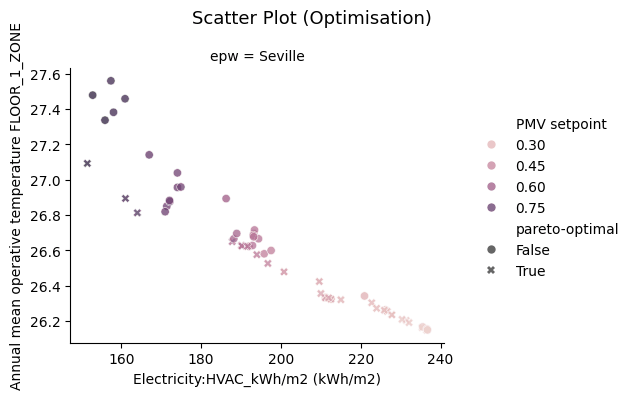

In [14]:
fig_pareto = optim.plot_parametric_scatter(
    x=main_energy_col,
    y=temperature_col,
    df_source="optimisation",
    hue="PMV setpoint",
    style="pareto-optimal",
    col="epw",
    out_dir=str(plot_out_dir),
    normalize_per_m2=False,
)
show_plot_output(fig_pareto)


### Reading the result

Open saved figures and verify that filters, grouping, and labels match your intended interpretation.

## WF5 aPMV optimization: choose compromise solutions

`plot_best_compromise_solutions` chooses solutions from the non-dominated set with three methods:
- knee point: the solution closest to the utopia point (the best value of each objective) after min-max normalisation of the objectives;
- TOPSIS with equal weights: the solution closest to the ideal and farthest from the anti-ideal solution, after normalising each objective by its vector norm. With these objectives it tends to the lowest-energy end of the front;
- TOPSIS with weights 0.7 and 0.3 for the HVAC electricity and the operative temperature.

The figure draws the two objectives of the non-dominated (blue) and dominated (grey) solutions, with the chosen ones marked: the horizontal axis is the HVAC electricity and the vertical one the annual mean operative temperature (°C), although the label of that axis repeats the energy unit. The table adds the share of hours with the aPMV within its setpoints of each chosen solution.

Key arguments used in this cell and why they matter:
- `out_dir`: folder of the figure and of `results_mcdm_best_solutions.csv`.

Variables created in this cell:
- `mcdm`: one row per weather file and method.

What to verify right after running this cell:
- Compare the parameters, the objectives and the hours within the setpoints of the solutions chosen by each method.


  [epw=Seville] Best compromise solutions:
    knee_point                | Electricity:HVAC_kWh/m2=196.7 kWh/m2 | Annual mean operative temperature FLOOR_1_ZONE=26.5
    topsis                    | Electricity:HVAC_kWh/m2=151.5 kWh/m2 | Annual mean operative temperature FLOOR_1_ZONE=27.1
    topsis_w70_30             | Electricity:HVAC_kWh/m2=151.5 kWh/m2 | Annual mean operative temperature FLOOR_1_ZONE=27.1

  MCDM summary saved: wf5_optimisation_apmv_results\plots\results_mcdm_best_solutions.csv


  MCDM plot saved: wf5_optimisation_apmv_results\plots\plot_mcdm_best_solutions.png


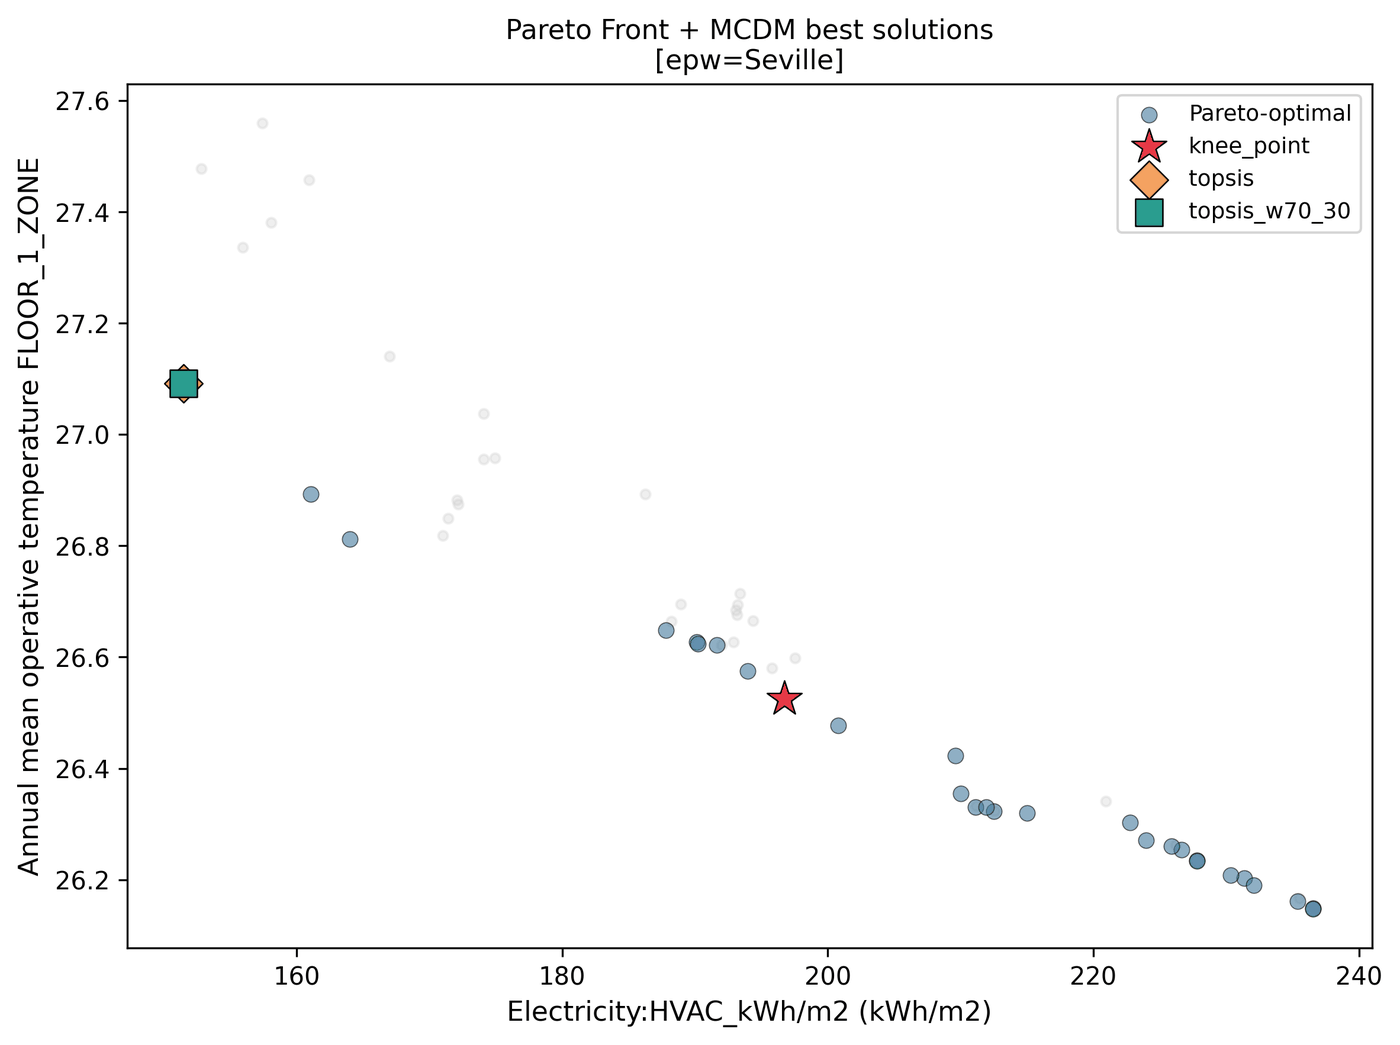

,selection,epw,Adaptive cooling coefficient,Adaptive heating coefficient,PMV setpoint,Electricity:HVAC_kWh/m2,Annual mean operative temperature FLOOR_1_ZONE,Share of hours within aPMV setpoints
0,Knee point,Seville,0.240,-0.407,0.472,196.734,26.525,0.948
1,"TOPSIS, equal weights",Seville,0.213,-0.446,0.881,151.491,27.092,0.966
2,"TOPSIS, 0.7 / 0.3",Seville,0.213,-0.446,0.881,151.491,27.092,0.966


In [15]:
mcdm = optim.plot_best_compromise_solutions(out_dir=str(plot_out_dir))
show_plot_output(plot_out_dir / "plot_mcdm_best_solutions.png")

selection_labels = {
    "knee_point": "Knee point",
    "topsis": "TOPSIS, equal weights",
    "topsis_w70_30": "TOPSIS, 0.7 / 0.3",
}
mcdm["selection"] = mcdm["mcdm_method"].map(selection_labels)
mcdm[comfort_col] = mcdm[[c for c in mcdm.columns if c.startswith("Hours within aPMV setpoints ")]].mean(axis=1) / 8760
mcdm[["selection", "epw"] + parameter_names + [main_energy_col, temperature_col, comfort_col]].round(3)


### Reading the result

Open saved figures and verify that filters, grouping, and labels match your intended interpretation.

## WF5 aPMV optimization: generate parallel-coordinates overview

This block generates parallel-coordinates plots to inspect the parameters and objectives of all the evaluations at once.

What to verify right after running this cell:
- Look for the parameter ranges of the non-dominated solutions.

  Parallel coordinates plot saved: wf5_optimisation_apmv_results\plots\plot_parallel_coordinates_Seville.png


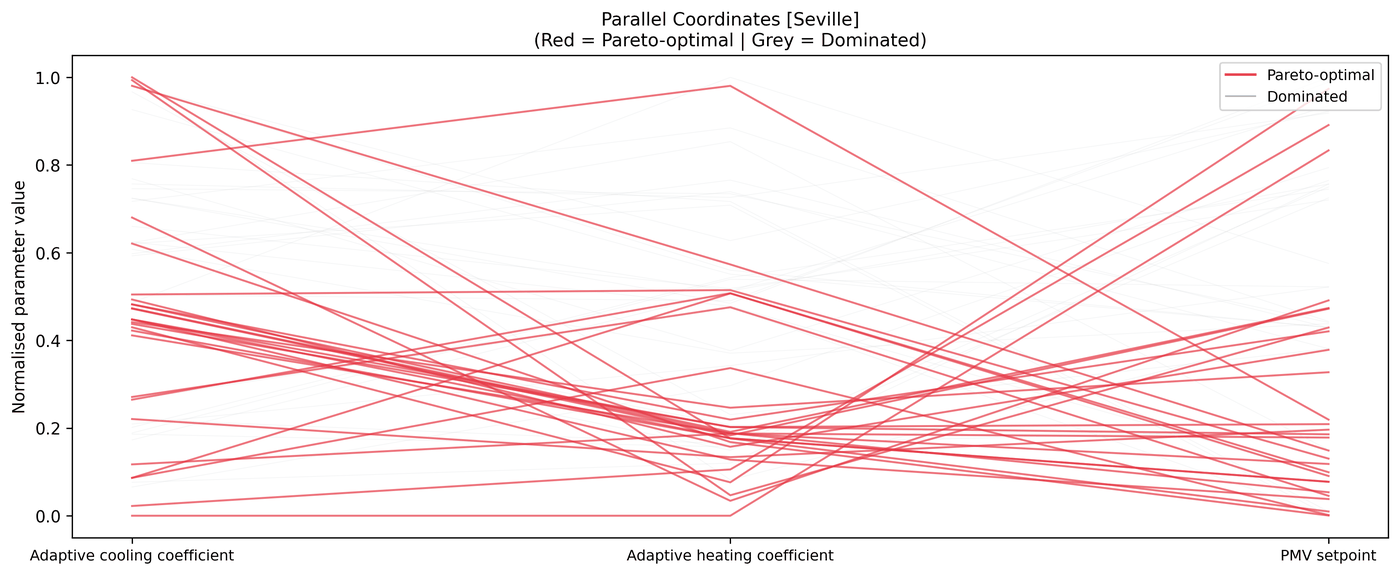

In [16]:
optim.plot_parallel_coordinates(out_dir=str(plot_out_dir))
for plot_path in sorted(plot_out_dir.glob("plot_parallel_coordinates_*.png")):
    show_plot_output(plot_path)


### Reading the result

Open saved figures and verify that filters, grouping, and labels match your intended interpretation.